In [1]:
import sys
sys.path.append('/home/pavel/pyadi-iio/')
sys.path.append('/home/pavel/libiio')
import adi
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Known pilot sequence for channel estimation (same sequence used at receiver)
# M-sequence (maximal-length) has good autocorrelation for sync and channel estimation

def m_sequence(length=63, taps=(6, 5)):
    """Generate m-sequence (maximal-length LFSR). length should be 2^n - 1."""
    n = int(np.log2(length + 1))
    reg = np.zeros(n, dtype=int)
    reg[0] = 1
    out = []
    for _ in range(length):
        out.append(reg[-1])
        feedback = reg[taps[0] - 1] ^ reg[taps[1] - 1]
        reg[1:] = reg[:-1]
        reg[0] = feedback
    return np.array(out)

def pilot_qpsk_symbols(num_pilot_symbols=64, seed=0):
    """Known QPSK symbols from deterministic pilot bits (reproducible at rx)."""
    np.random.seed(seed)
    # Use fixed seed so tx and rx get identical sequence
    bits_i = m_sequence(63)  # I branch
    bits_q = np.roll(m_sequence(63), 17)  # Q branch, shifted for different pattern
    # Extend to num_pilot_symbols, map to QPSK (0,1,2,3) -> 45, 135, 225, 315 deg
    n = num_pilot_symbols
    idx = np.arange(n) % 63
    x_int = (bits_i[idx] * 2 + bits_q[idx]).astype(int)
    x_degrees = x_int * 360 / 4.0 + 45
    x_radians = x_degrees * np.pi / 180.0
    return np.cos(x_radians) + 1j * np.sin(x_radians)

# Parameters for channel estimation waveform (match receiver)
sample_rate = 1e6   # Hz
center_freq = 915e6 # Hz
num_pilot_symbols = 128
samples_per_symbol = 16
pilot_symbols = pilot_qpsk_symbols(num_pilot_symbols)
pilot_samples = np.repeat(pilot_symbols, samples_per_symbol)  # baseband, not yet scaled

In [6]:
# Create radio (sample_rate, center_freq set in pilot cell)
sdr = adi.ad9363("ip:192.168.2.1")

sdr.sample_rate = int(sample_rate)
sdr.tx_enabled_channels = [0, 1]
sdr.tx_rf_bandwidth = int(sample_rate) # filter cutoff, just set it to the same as sample rate
sdr.tx_lo = int(center_freq)

sdr.gain_control_mode_chan0 = "manual"
sdr.gain_control_mode_chan1 = "manual"
sdr.tx_hardwaregain_chan0 = int(0)
sdr.tx_hardwaregain_chan1 = int(0)
sdr.tx_cyclic_buffer = True

# Transmit KNOWN pilot waveform for channel estimation (receiver uses same sequence)
samples = pilot_samples.copy()
samples = samples.astype(np.complex64) * (2**14)  # PlutoSDR scale [-2^14, 2^14]

samples_full = np.zeros((2, samples.shape[0]), dtype=np.complex64)
samples_full[0, :] = samples
samples_full[1, :] = samples

# Start cyclic transmission of pilot (receiver correlates with pilot_symbols to estimate channel)
sdr.tx(samples_full)

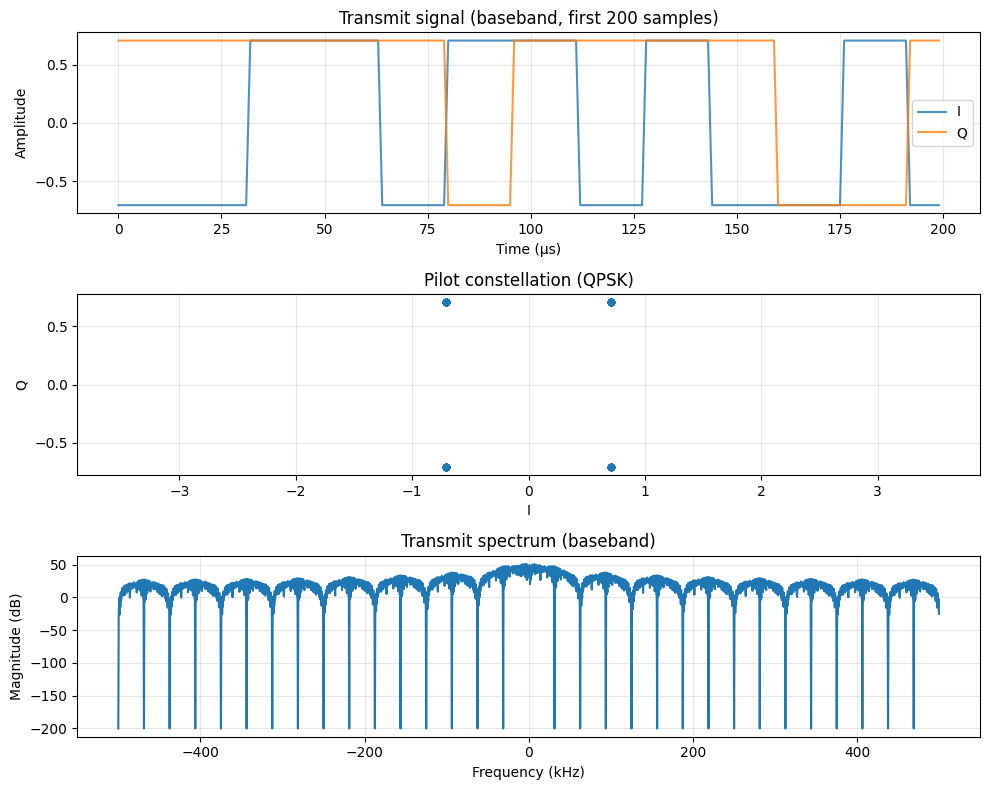

In [4]:
# Plot transmitting signal (pilot waveform) — run after pilot cell
fig, axes = plt.subplots(3, 1, figsize=(10, 8))

n_show = min(200, len(pilot_samples))
t_us = np.arange(n_show) / sample_rate * 1e6
axes[0].plot(t_us, np.real(pilot_samples[:n_show]), label='I', alpha=0.8)
axes[0].plot(t_us, np.imag(pilot_samples[:n_show]), label='Q', alpha=0.8)
axes[0].set_xlabel('Time (µs)'); axes[0].set_ylabel('Amplitude'); axes[0].legend(); axes[0].set_title('Transmit signal (baseband, first 200 samples)')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(np.real(pilot_symbols), np.imag(pilot_symbols), alpha=0.6, s=20)
axes[1].set_xlabel('I'); axes[1].set_ylabel('Q'); axes[1].set_title('Pilot constellation (QPSK)'); axes[1].axis('equal'); axes[1].grid(True, alpha=0.3)

N = len(pilot_samples)
spectrum = np.fft.fftshift(np.fft.fft(pilot_samples))
f_axis = np.fft.fftshift(np.fft.fftfreq(N, 1 / sample_rate)) / 1e3
axes[2].plot(f_axis, 20 * np.log10(np.abs(spectrum) + 1e-10))
axes[2].set_xlabel('Frequency (kHz)'); axes[2].set_ylabel('Magnitude (dB)'); axes[2].set_title('Transmit spectrum (baseband)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

In [ ]:
# Передача с непрерывным отображением передаваемого сигнала (остановить: Interrupt Kernel)
# Сначала выполните ячейку с sdr.tx(samples_full) выше
try:
    sdr.tx(samples_full)
except Exception:
    pass  # уже передаём

plt.ion()
fig, axes = plt.subplots(3, 1, figsize=(10, 8))
n_show = min(256, len(pilot_samples))
t_us = (np.arange(n_show) / sample_rate) * 1e6
line_i, = axes[0].plot(t_us, np.real(pilot_samples[:n_show]), 'b-', label='I', alpha=0.8)
line_q, = axes[0].plot(t_us, np.imag(pilot_samples[:n_show]), 'r-', label='Q', alpha=0.8)
axes[0].set_xlabel('Время (µs)'); axes[0].set_ylabel('Амплитуда'); axes[0].legend(); axes[0].set_title('Передаваемый сигнал (база, скользящее окно)')
axes[0].grid(True, alpha=0.3); axes[0].set_ylim([-1.5, 1.5])

scat = axes[1].scatter(np.real(pilot_symbols), np.imag(pilot_symbols), alpha=0.6, s=20)
axes[1].set_xlabel('I'); axes[1].set_ylabel('Q'); axes[1].set_title('Созвездие пилотов (QPSK)'); axes[1].axis('equal'); axes[1].grid(True, alpha=0.3)

N = len(pilot_samples)
f_axis = np.fft.fftshift(np.fft.fftfreq(N, 1 / sample_rate)) / 1e3
spectrum = np.fft.fftshift(np.fft.fft(pilot_samples))
line_spec, = axes[2].plot(f_axis, 20 * np.log10(np.abs(spectrum) + 1e-10))
axes[2].set_xlabel('Частота (кГц)'); axes[2].set_ylabel('Магнитуда (дБ)'); axes[2].set_title('Спектр передаваемого сигнала'); axes[2].grid(True, alpha=0.3)

total = len(pilot_samples)
frame = 0
try:
    while True:
        offset = (frame * 8) % total  # скользящее окно
        idx = np.arange(n_show) + offset
        window = pilot_samples[idx % total]
        line_i.set_ydata(np.real(window))
        line_q.set_ydata(np.imag(window))
        fig.canvas.draw(); fig.canvas.flush_events()
        plt.pause(0.05)
        frame += 1
except KeyboardInterrupt:
    pass
plt.ioff(); plt.show()

In [5]:
# Stop transmitting
sdr.tx_destroy_buffer()

In [5]:
samples.shape[0]

2048

In [6]:
# Stop transmitting
sdr.tx_destroy_buffer()

In [8]:
# Create radio
sdr = adi.ad9363("ip:192.168.2.1")

sample_rate = 20e6 # Hz
center_freq = 2.0e9 # Hz

sdr.tx_enabled_channels = [0, 1]
tti_len = 1024
num_samps = tti_len * 20 # number of samples returned per call to rx()

sdr.gain_control_mode_chan0 = "manual"
sdr.gain_control_mode_chan1 = "manual"
sdr.tx_hardwaregain_chan0 = int(0)
sdr.tx_hardwaregain_chan1 = int(0)
sdr.tx_rf_bandwidth = int(sample_rate)
sdr.sample_rate = int(sample_rate)
sdr.tx_lo = int(center_freq)
sdr.tx_cyclic_buffer = True

samples_full = np.zeros((2,samples.shape[0]), dtype=np.complex64)
samples_full[0,:] = samples
samples_full[1,:] = samples * 1
samples_full *= 2**14 # The PlutoSDR expects samples to be between -2^14 and +2^14, not -1 and +1 like some SDRs

# Transmit our batch of samples 100 times, so it should be 1 second worth of samples total, if USB can keep up
sdr.tx(samples_full) # start transmitting

ERROR: Open unlocked: -16


OSError: [Errno 16] Device or resource busy

In [ ]:
# Stop transmitting
sdr.tx_destroy_buffer()